# IPCA – Análises Avançadas

Neste notebook vamos realizar quatro análises fundamentais:

1. Difusão da inflação  
2. Núcleos de inflação (core inflation)  
3. Heatmap de choques setoriais  
4. Persistência inflacionária (momentum)

Todas as análises são baseadas nos **subitens**, que são o nível mais granular do IPCA.

## 1. Setup

In [5]:
import sys, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.database.connection import engine

ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.append(ROOT)

print("PYTHONPATH atualizado:", ROOT)

pd.set_option("display.float_format", "{:.6f}".format)


PYTHONPATH atualizado: /home/moacir/projects/ml/analytics/inflation


## 2. Carregar subitens (índice cheio + peso)

In [10]:
query_subitens = """
select
    date::date,
    category        as "idSubItem",
    category_name   as "subItem",
    indice          as "indiceCheio",
    peso,
    (indice * (peso / 100)) as contribuicao
from bcb.ipca_subitens
order by date desc, category;
"""

df = pd.read_sql(query_subitens, engine)
df.head()

,date,idSubItem,subItem,indiceCheio,peso,contribuicao
0,2026-03-01,1101002,Arroz,-0.300000,0.498800,-0.001496
1,2026-03-01,1101051,Feijão - mulatinho,4.420000,0.012300,0.000544
2,2026-03-01,1101052,Feijão - preto,7.120000,0.035900,0.002556
3,2026-03-01,1101053,Feijão - macáçar (fradinho),2.290000,0.016000,0.000366
4,2026-03-01,1101073,Feijão - carioca (rajado),15.400000,0.109400,0.016848


# ANÁLISE 1 — Difusão da inflação

- Difusão responde:
    > Quantos subitens subiram de preço no mês?

$ \qquad \to$ **Difusão alta** → inflação espalhada  
$ \qquad \to$ **Difusão baixa** → inflação concentrada em poucos itens

$ \qquad \to Difusão = $ $ \frac{ nº \ de \ subitens \ com \ alta }{total \ de \ subitens} $ 

In [15]:
df["alta"] = df["indiceCheio"] > 0

df_difusao = (
    df.groupby("date")["alta"].mean().reset_index().rename(columns={"alta": "difusao"})
)

df_difusao["difusao"] *= 100
df_difusao.tail()

,date,difusao
70,2025-11-01,55.702918
71,2025-12-01,60.477454
72,2026-01-01,63.925729
73,2026-02-01,61.273210
74,2026-03-01,67.374005


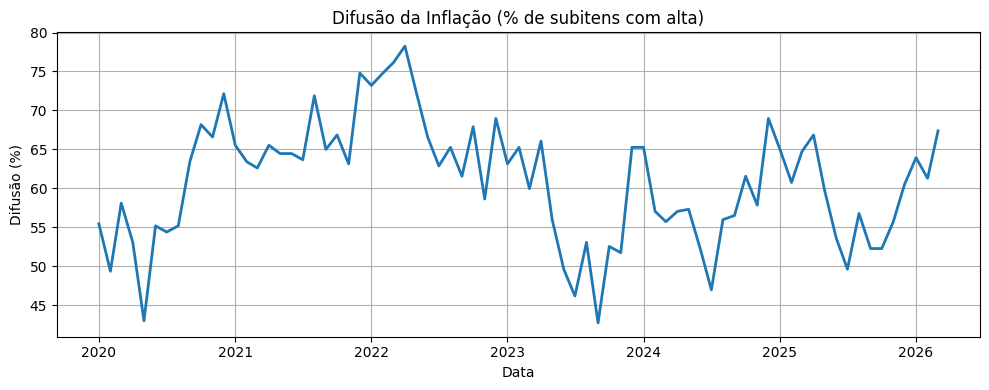

In [46]:
plt.figure(figsize=(10, 4))
plt.plot(df_difusao["date"], df_difusao["difusao"], linewidth=2)
plt.title("Difusão da Inflação (% de subitens com alta)")
plt.ylabel("Difusão (%)")
plt.xlabel("Data")
plt.grid(True)
plt.tight_layout()
plt.show()

# ANÁLISE 2 — Núcleos de inflação (média aparada)

Núcleo por média aparada:
- ordena subitens por índice
- remove extremos (ex: 20% mais baixos e 20% mais altos)
- calcula média ponderada do miolo

In [47]:
def trimmed_mean(group: pd.DataFrame, trim: float = 0.2) -> float:
    g = group.sort_values("indiceCheio")
    n = len(g)
    k = int(n * trim)
    if 2 * k >= n:
        return np.nan
    g2 = g.iloc[k : n - k]
    return np.average(g2["indiceCheio"], weights=g2["peso"])


df_trim = (
    df.groupby("date")
    .apply(trimmed_mean)
    .reset_index()
    .rename(columns={0: "nucleo_aparado"})
)

df_trim.tail()

,date,nucleo_aparado
70,2025-11-01,0.173768
71,2025-12-01,0.302599
72,2026-01-01,0.404807
73,2026-02-01,0.346208
74,2026-03-01,0.423918


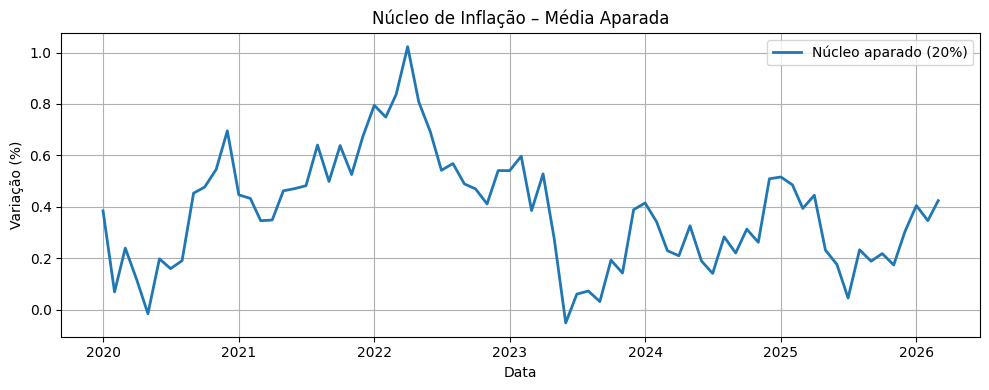

In [49]:
plt.figure(figsize=(10, 4))
plt.plot(df_trim["date"], df_trim["nucleo_aparado"], label="Núcleo aparado (20%)", linewidth=2)
plt.title("Núcleo de Inflação – Média Aparada")
plt.xlabel("Data")
plt.ylabel("Variação (%)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ANÁLISE 3 — Heatmap de choques setoriais

Aqui olhamos:
> Quanto cada grupo contribuiu para o IPCA, mês a mês?

In [51]:
query_groups = """
SELECT
    g.date::date,
    g.grupos,
    (si.indice * (si.peso / 100)) AS contribuicao
FROM bcb.ipca_subitens si
LEFT JOIN bcb."vw_groupsBySubItems" g
    ON g."idSubItens" = si.category
    AND g.date = si.date;
"""

dfg = pd.read_sql(query_groups, engine)

df_heat = (
    dfg.groupby(["date", "grupos"])["contribuicao"]
    .sum()
    .reset_index()
    .pivot(index="date", columns="grupos", values="contribuicao")
)

df_heat.tail()

grupos,Alimentação e bebidas,Artigos de residência,Comunicação,Despesas pessoais,Educação,Habitação,Saúde e cuidados pessoais,Transportes,Vestuário
date,,,,,,,,,
2025-11-01,-0.002213,-0.035237,-0.009021,0.078889,0.000604,0.081164,-0.005534,0.044245,0.022978
2025-12-01,0.058288,0.022279,0.016963,0.037535,0.004556,-0.051909,0.070606,0.149510,0.021355
2026-01-01,0.049072,0.007006,0.037360,0.041991,0.001136,-0.016557,0.095767,0.121977,-0.011878
2026-02-01,0.056227,0.004432,0.006925,0.034130,0.314497,0.045413,0.081074,0.150716,0.007232
2026-03-01,0.333288,0.017700,0.008520,0.066579,0.001352,0.033870,0.056706,0.335956,0.021262


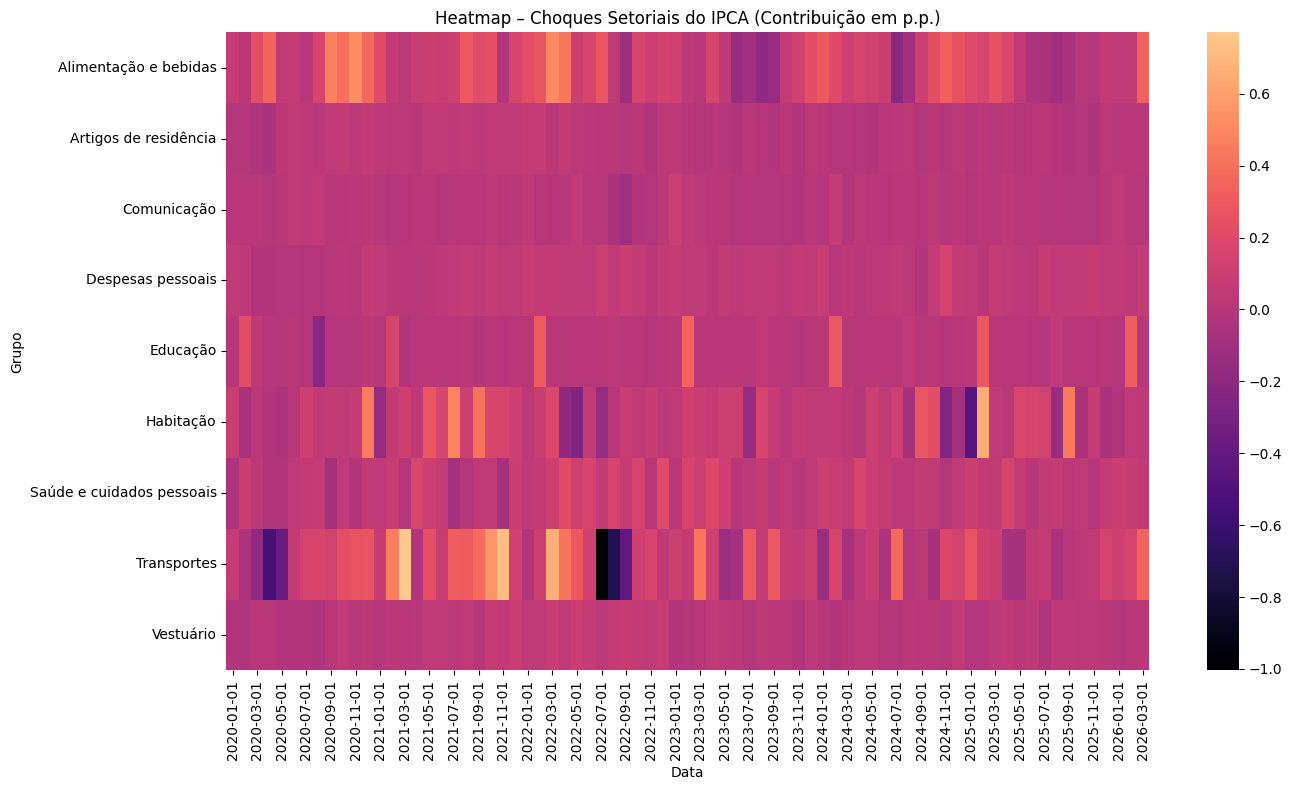

In [52]:
plt.figure(figsize=(14, 8))
sns.heatmap(df_heat.T, cmap="magma", center=0)
plt.title("Heatmap – Choques Setoriais do IPCA (Contribuição em p.p.)")
plt.xlabel("Data")
plt.ylabel("Grupo")
plt.tight_layout()
plt.show()

# ANÁLISE 4 — Persistência inflacionária (momentum)

Momentum responde:
> A inflação está acelerando ou desacelerando?

Usamos uma média móvel de 3 meses.

In [103]:
df_ipca = pd.read_sql(
    "SELECT date::date, indice AS ipca FROM bcb.ipca WHERE date >= '2025-01-01' ORDER BY date", engine
)

df_ipca["momentum_3m"] = df_ipca["ipca"].rolling(3).mean()
df_ipca.sort_values("date", ascending=False).head(10)

,date,ipca,momentum_3m
14,2026-03-01,0.880000,0.636667
13,2026-02-01,0.700000,0.453333
12,2026-01-01,0.330000,0.280000
11,2025-12-01,0.330000,0.200000
10,2025-11-01,0.180000,0.250000
9,2025-10-01,0.090000,0.153333
8,2025-09-01,0.480000,0.210000
7,2025-08-01,-0.110000,0.130000
6,2025-07-01,0.260000,0.253333
5,2025-06-01,0.240000,0.310000


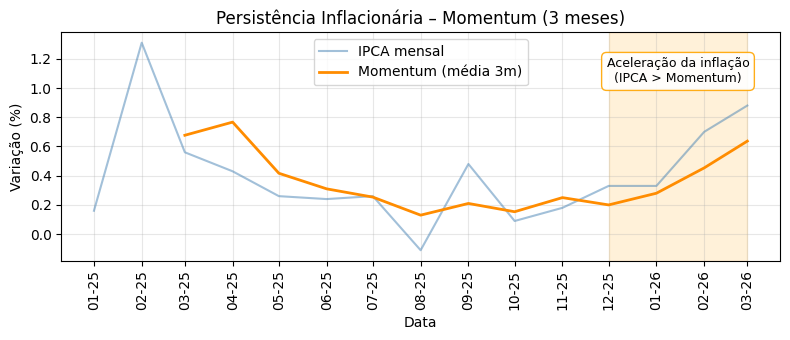

In [ ]:
df_ipca["date"] = pd.to_datetime(df_ipca["date"])

# Aceleração: IPCA > Momentum e momentum não nulo
df_ipca["acelera"] = (df_ipca["ipca"] > df_ipca["momentum_3m"]) & df_ipca["momentum_3m"].notna()
# Se não houver aceleração, não destacamos nada
inicio = fim = None

if df_ipca["acelera"].any():
    # índice do último ponto com aceleração
    last_idx = df_ipca[df_ipca["acelera"]].index.max()
    fim = df_ipca.loc[last_idx, "date"]

    # voltar até onde o bloco contínuo de aceleração começou
    first_idx = last_idx
    while first_idx - 1 in df_ipca.index and df_ipca.loc[first_idx - 1, "acelera"]:
        first_idx -= 1

    inicio = df_ipca.loc[first_idx, "date"]

plt.figure(figsize=(8, 3.5))
plt.plot(df_ipca["date"], df_ipca["ipca"], label="IPCA mensal", alpha=0.5, color="steelblue")
plt.plot(df_ipca["date"], df_ipca["momentum_3m"], label="Momentum (média 3m)", linewidth=2, color="darkorange")

# --- Destacar o último período de aceleração ---
if inicio is not None and fim is not None:
    plt.axvspan(inicio, fim, color="orange", alpha=0.15)
    # Posição do quadro (meio da faixa)
    meio = inicio + (fim - inicio) / 2

    # --- QUADRO estilo hue ---
    plt.text(meio, df_ipca["ipca"].max() * 0.85,   # posição vertical
        "Aceleração da inflação\n(IPCA > Momentum)", ha="center", va="center", fontsize=9, color="black",
        bbox=dict( boxstyle="round,pad=0.4", facecolor="white", edgecolor="orange", alpha=0.9)
    )

# --- Eixo X rotacionado 90º ---
plt.xticks(ticks=df_ipca["date"], labels=df_ipca["date"].dt.strftime("%m-%y"), rotation=90)

plt.title("Persistência Inflacionária – Momentum (3 meses)")
plt.xlabel("Data"); plt.ylabel("Variação (%)"); plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
plt.show()


# Conclusões

- **Difusão** mostra se a inflação está espalhada entre muitos subitens ou concentrada em poucos.  
- **Núcleo aparado** filtra choques extremos e revela a tendência subjacente da inflação.  
- **Heatmap setorial** mostra, mês a mês, quais grupos mais contribuíram para o IPCA.  
- **Momentum** captura a persistência: se a inflação está acelerando ou perdendo força.

A partir daqui, você pode:
- cruzar essas métricas com SELIC  
- comparar períodos de aperto/afrouxamento monetário  
- construir modelos (VAR, ARIMA, etc.) usando essas séries como insumos.